# Nhiệm vụ 1: Bài Toán N Quân Hậu (N-Queen)

Đánh giá thực nghiệm mô hình hóa Logic mệnh đề dạng chuẩn hội (CNF) giải bằng `Glucose3` (`PySAT`) và đối sánh hai chiến lược chọn biến trong thuật toán tìm kiếm cục bộ `Min-Conflicts`.

In [1]:
import sys
import random
from pathlib import Path
from statistics import mean

import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams['font.sans-serif'] = ['Segoe UI', 'Arial', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

current = Path.cwd().resolve()
for candidate in (current, *current.parents):
    if (candidate / 'task1' / 'board.py').exists():
        source_dir = candidate
        break
    if (candidate / 'source' / 'task1' / 'board.py').exists():
        source_dir = candidate / 'source'
        break
else:
    raise RuntimeError('Không tìm thấy thư mục source/task1')

if str(source_dir) not in sys.path:
    sys.path.insert(0, str(source_dir))

from task1.board import NQueenBoard
from task1.cnf_encoder import NQueenCNFEncoder
from task1.sat_solver import Glucose3NQueenSolver
from task1.min_conflicts import (
    MinConflictsSolver,
    RandomConflictedSelector,
    TabuMaxConflictSelector,
)

figure_dir = source_dir.parent / 'report' / 'figures'
figure_dir.mkdir(parents=True, exist_ok=True)
print('Đã khởi tạo môi trường thực nghiệm Nhiệm vụ 1 thành công.')

Đã khởi tạo môi trường thực nghiệm Nhiệm vụ 1 thành công.


## 1. Thực Nghiệm Bộ Giải SAT Glucose3 (Logic Mệnh Đề CNF)

Mỗi ô trên bàn cờ $N \times N$ được gán một biến logic mệnh đề. Tổng số mệnh đề CNF và thời gian chạy được thống kê trên dải kích thước $N \in [4, 60]$.

In [2]:
sat_sizes = [4, 8, 12, 16, 20, 25, 30, 35, 40, 50, 60]
sat_rows = []
for n in sat_sizes:
    result = Glucose3NQueenSolver().solve(n)
    assert result.satisfiable and result.board.is_valid_solution()
    assert result.num_clauses == NQueenCNFEncoder(n).theoretical_clause_count()
    sat_rows.append({
        'Kích thước N': n,
        'Số biến (N^2)': result.num_variables,
        'Tổng số mệnh đề CNF': result.num_clauses,
        'Thời gian mã hóa (ms)': round(result.encoding_time_sec * 1000, 2),
        'Thời gian giải Glucose3 (ms)': round(result.solve_time_sec * 1000, 2),
        'Nghiệm hợp lệ': 'Đúng' if result.board.is_valid_solution() else 'Sai',
    })
sat_results = pd.DataFrame(sat_rows)
sat_results

,Kích thước N,Số biến (N^2),Tổng số mệnh đề CNF,Thời gian mã hóa (ms),Thời gian giải Glucose3 (ms),Nghiệm hợp lệ
0,4,16,84,0.39,1.72,Đúng
1,8,64,744,0.65,1.25,Đúng
2,12,144,2620,1.65,3.34,Đúng
3,16,256,6352,3.87,24.17,Đúng
4,20,400,12580,4.42,13.34,Đúng
5,25,625,24850,10.25,44.83,Đúng
6,30,900,43270,114.15,53.40,Đúng
7,35,1225,69090,33.05,241.66,Đúng
8,40,1600,103560,103.98,136.02,Đúng
9,50,2500,203450,302.41,286.57,Đúng


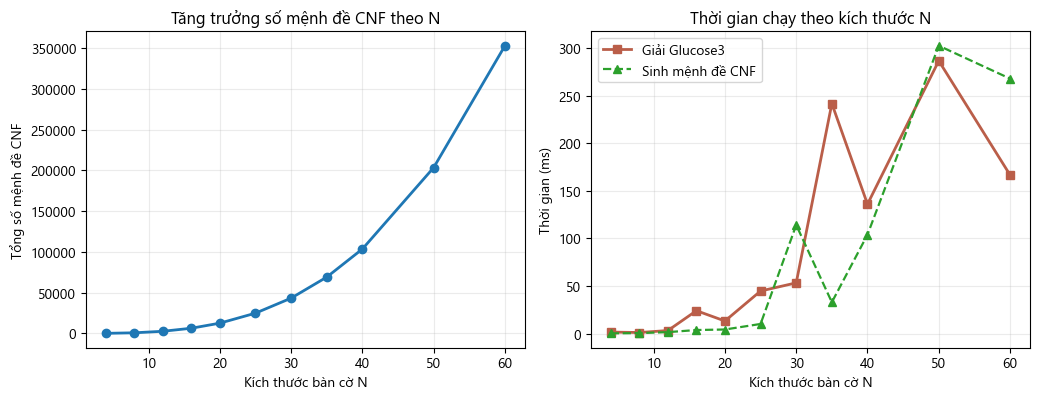

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.1))
axes[0].plot(sat_results['Kích thước N'], sat_results['Tổng số mệnh đề CNF'], marker='o', linewidth=2)
axes[0].set(xlabel='Kích thước bàn cờ N', ylabel='Tổng số mệnh đề CNF', title='Tăng trưởng số mệnh đề CNF theo N')

axes[1].plot(sat_results['Kích thước N'], sat_results['Thời gian giải Glucose3 (ms)'], marker='s', linewidth=2, color='#ba5e49', label='Giải Glucose3')
axes[1].plot(sat_results['Kích thước N'], sat_results['Thời gian mã hóa (ms)'], marker='^', linestyle='--', linewidth=1.6, color='#2ca02c', label='Sinh mệnh đề CNF')
axes[1].set(xlabel='Kích thước bàn cờ N', ylabel='Thời gian (ms)', title='Thời gian chạy theo kích thước N')
axes[1].legend()
for axis in axes:
    axis.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(figure_dir / 'task1_glucose3_scaling.png', dpi=180)
plt.show()

## 2. Thực Nghiệm Đối Sánh Min-Conflicts Chuẩn Và Heuristic Đề Xuất

Hai phương pháp cùng xuất phát trên 30 bàn cờ khởi tạo ngẫu nhiên giống nhau cho mỗi kích thước $N$, giới hạn tối đa 2.500 bước.

In [4]:
sizes = [8, 16, 32, 64, 100, 150]
trials = 30
max_steps = 2500
local_rows = []
for n in sizes:
    boards = [NQueenBoard.from_random(n, random.Random(2026 + n * 131 + i)) for i in range(trials)]
    for label, selector in [
        ('Min-Conflicts chuẩn (Ngẫu nhiên)', RandomConflictedSelector()),
        ('Max-Conflict + Tabu (Đề xuất)', TabuMaxConflictSelector()),
    ]:
        solver = MinConflictsSolver(selector, max_steps=max_steps)
        runs = [solver.solve(n, initial_board=board, seed=9000 + i) for i, board in enumerate(boards)]
        ok_cnt = sum(r.solved and r.board.is_valid_solution() for r in runs)
        local_rows.append({
            'Kích thước N': n,
            'Phương pháp': label,
            'Tỷ lệ thành công (%)': round(100 * ok_cnt / trials, 2),
            'Số bước trung bình': round(mean(r.steps for r in runs), 2),
            'Thời gian TB (ms)': round(1000 * mean(r.elapsed_sec for r in runs), 2),
        })
local_results = pd.DataFrame(local_rows)
local_results

,Kích thước N,Phương pháp,Tỷ lệ thành công (%),Số bước trung bình,Thời gian TB (ms)
0,8,Min-Conflicts chuẩn (Ngẫu nhiên),100.00,44.37,0.68
1,8,Max-Conflict + Tabu (Đề xuất),93.33,181.67,4.41
2,16,Min-Conflicts chuẩn (Ngẫu nhiên),100.00,96.00,2.48
3,16,Max-Conflict + Tabu (Đề xuất),100.00,30.73,1.29
4,32,Min-Conflicts chuẩn (Ngẫu nhiên),100.00,90.57,6.59
5,32,Max-Conflict + Tabu (Đề xuất),100.00,45.97,2.49
6,64,Min-Conflicts chuẩn (Ngẫu nhiên),100.00,107.17,10.69
7,64,Max-Conflict + Tabu (Đề xuất),100.00,63.27,9.70
8,100,Min-Conflicts chuẩn (Ngẫu nhiên),100.00,138.67,18.56
9,100,Max-Conflict + Tabu (Đề xuất),100.00,88.40,18.42


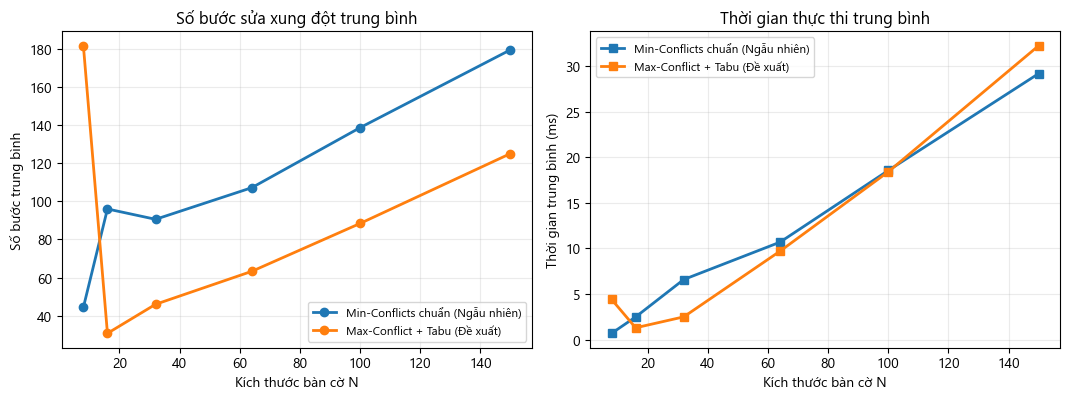

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.1))
for method, group in local_results.groupby('Phương pháp', sort=False):
    axes[0].plot(group['Kích thước N'], group['Số bước trung bình'], marker='o', linewidth=2, label=method)
    axes[1].plot(group['Kích thước N'], group['Thời gian TB (ms)'], marker='s', linewidth=2, label=method)
axes[0].set(xlabel='Kích thước bàn cờ N', ylabel='Số bước trung bình', title='Số bước sửa xung đột trung bình')
axes[1].set(xlabel='Kích thước bàn cờ N', ylabel='Thời gian trung bình (ms)', title='Thời gian thực thi trung bình')
for axis in axes:
    axis.grid(alpha=0.25)
    axis.legend(fontsize=8.5)
fig.tight_layout()
fig.savefig(figure_dir / 'task1_min_conflicts_comparison.png', dpi=180)
plt.show()